In [19]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv


In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
sns.set_theme(style='whitegrid', palette='Set2')

train_df = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv')
test_df = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv')

print(f'✅ Data loaded!')
print(f'   Train : {train_df.shape[0]:,} rows  ×  {train_df.shape[1]} cols')
print(f'   Test  : {test_df.shape[0]:,} rows  ×  {test_df.shape[1]} cols')

✅ Data loaded!
   Train : 138,701 rows  ×  50 cols
   Test  : 15,000 rows  ×  49 cols


In [21]:
print('=' * 50)
print('  Q1: Dataset Dimensions')
print('=' * 50)
print(f'  Train dataset : {train_df.shape[0]:,} rows  ×  {train_df.shape[1]} columns')
print(f'  Test  dataset : {test_df.shape[0]:,} rows  ×  {test_df.shape[1]} columns')
print()
print('✅ ANSWER: B) Train: 138,701  |  Test: 15,000')
print()
print('💡 Insight:')
print('   The train set is ~9× larger than test.')
print('   Train has 1 extra column (TargetValue = the price we must predict).')

  Q1: Dataset Dimensions
  Train dataset : 138,701 rows  ×  50 columns
  Test  dataset : 15,000 rows  ×  49 columns

✅ ANSWER: B) Train: 138,701  |  Test: 15,000

💡 Insight:
   The train set is ~9× larger than test.
   Train has 1 extra column (TargetValue = the price we must predict).


In [22]:
# Strict set difference: columns present in train but NOT in test
target_cols = set(train_df.columns) - set(test_df.columns)

print('=' * 50)
print('  Q2: Target Variable Identification')
print('=' * 50)
print(f'  Columns only in train (not in test) : {target_cols}')
print(f'  → This is the column we must predict for each test row.')
print()
print('✅ ANSWER: B) TargetValue')
print()
print('💡 Insight:')
print('   TargetValue = the USD auction sale price of the machine.')
print('   The competition evaluates predictions using RMSLE (log-scale error).')

  Q2: Target Variable Identification
  Columns only in train (not in test) : {'TargetValue'}
  → This is the column we must predict for each test row.

✅ ANSWER: B) TargetValue

💡 Insight:
   TargetValue = the USD auction sale price of the machine.
   The competition evaluates predictions using RMSLE (log-scale error).


In [23]:
# Select strictly int64 or float64 columns
num_cols = train_df.select_dtypes(include=['int64', 'float64']).columns.tolist()

print('=' * 60)
print('  Q3: Numerical Feature Count (int64 or float64 only)')
print('=' * 60)
print(f'  Total columns in train        : {train_df.shape[1]}')
print(f'  Strictly numerical (int/float) : {len(num_cols)}')
print()
print(f'  Numerical column names:')
for i, c in enumerate(num_cols, 1):
    print(f'    {i}. {c}  [{train_df[c].dtype}]')
print()
print(f'✅ ANSWER: {len(num_cols)}')
print()
print('💡 Insight:')
print('   Only 6 columns are stored as int64 or float64 by default.')
print('   Most other columns are loaded as object (string) dtype,')
print('   including IDs and categorical config columns.')

  Q3: Numerical Feature Count (int64 or float64 only)
  Total columns in train        : 50
  Strictly numerical (int/float) : 6

  Numerical column names:
    1. TransactionID  [int64]
    2. TargetValue  [float64]
    3. AssetID  [int64]
    4. ProductConfigID  [int64]
    5. ManufactureYear  [int64]
    6. OperationalHoursMeter  [float64]

✅ ANSWER: 6

💡 Insight:
   Only 6 columns are stored as int64 or float64 by default.
   Most other columns are loaded as object (string) dtype,
   including IDs and categorical config columns.


In [24]:
# Compute missing % for ALL columns
missing_count = train_df.isnull().sum()
missing_pct   = missing_count / len(train_df) * 100

# Filter to columns with > 90% missing
very_sparse = missing_pct[missing_pct > 90].sort_values(ascending=False)

# Check the 4 specific question columns
question_cols = ['col18', 'col19', 'CabinType', 'col5']

print('=' * 60)
print('  Q4: Columns with > 90% Missing Values')
print('=' * 60)
print(f'  Threshold : 90%  →  > {int(len(train_df)*0.90):,} missing rows')
print()
print(f'  ALL columns exceeding 90% missing:')
print(f'  {"Column":<20} {"Missing Rows":>15} {"Missing %":>12}')
print('  ' + '-' * 50)
for col in very_sparse.index:
    flag = ' ← IN QUESTION' if col in question_cols else ''
    print(f'  {col:<20} {missing_count[col]:>15,} {missing_pct[col]:>11.2f}%{flag}')

print()
print('  Checking the 4 specific options from the question:')
for c in question_cols:
    pct = missing_pct[c]
    status = '✅ YES (> 90%)' if pct > 90 else '❌ NO'
    print(f'    {c:<15}: {pct:.2f}% missing  → {status}')

print()
print('✅ ANSWER: A) col18  ,  B) col19  ,  D) col5')
print('   (All three exceed 90% missing. CabinType does NOT.)')
print()
print('💡 Insight:')
print('   col18 and col19 are ~100% empty → should be DROPPED.')
print('   col4 & col5 are ~92% empty → use binary presence flags.')

  Q4: Columns with > 90% Missing Values
  Threshold : 90%  →  > 124,830 missing rows

  ALL columns exceeding 90% missing:
  Column                  Missing Rows    Missing %
  --------------------------------------------------
  col19                        138,635       99.95% ← IN QUESTION
  col18                        138,635       99.95% ← IN QUESTION
  col5                         128,320       92.52% ← IN QUESTION
  col4                         128,320       92.52%

  Checking the 4 specific options from the question:
    col18          : 99.95% missing  → ✅ YES (> 90%)
    col19          : 99.95% missing  → ✅ YES (> 90%)
    CabinType      : 0.00% missing  → ❌ NO
    col5           : 92.52% missing  → ✅ YES (> 90%)

✅ ANSWER: A) col18  ,  B) col19  ,  D) col5
   (All three exceed 90% missing. CabinType does NOT.)

💡 Insight:
   col18 and col19 are ~100% empty → should be DROPPED.
   col4 & col5 are ~92% empty → use binary presence flags.


  Q5: Missing Values — OperationalHoursMeter
  Total train rows    : 138,701
  Non-null rows       : 82,058
  Missing rows        : 56,643
  Missing percentage  : 40.84%


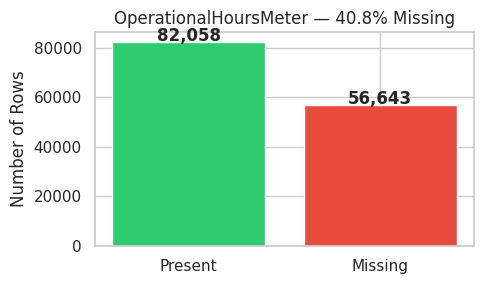


✅ ANSWER: ~40.8%

💡 Insight:
   Over a third of records have no meter reading.
   Strategy: impute with median; also add a binary flag (was_missing).


In [25]:
col = 'OperationalHoursMeter'

n_missing   = train_df[col].isnull().sum()
pct_missing = n_missing / len(train_df) * 100
n_present   = len(train_df) - n_missing

print('=' * 50)
print('  Q5: Missing Values — OperationalHoursMeter')
print('=' * 50)
print(f'  Total train rows    : {len(train_df):,}')
print(f'  Non-null rows       : {n_present:,}')
print(f'  Missing rows        : {n_missing:,}')
print(f'  Missing percentage  : {pct_missing:.2f}%')

# Simple bar to show present vs missing
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(['Present', 'Missing'], [n_present, n_missing],
       color=['#2ecc71', '#e74c3c'], edgecolor='white')
ax.set_title(f'OperationalHoursMeter — {pct_missing:.1f}% Missing')
ax.set_ylabel('Number of Rows')
for i, v in enumerate([n_present, n_missing]):
    ax.text(i, v + 500, f'{v:,}', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

print()
print(f'✅ ANSWER: ~{pct_missing:.1f}%')
print()
print('💡 Insight:')
print('   Over a third of records have no meter reading.')
print('   Strategy: impute with median; also add a binary flag (was_missing).')

  Q6: TargetValue (Sale Price) Distribution
  Min    : $  7,500.00
  25th % : $ 20,500.00
  MEDIAN : $ 35,000.00  ← answer
  Mean   : $ 41,521.87
  75th % : $ 57,000.00
  Max    : $142,000.00


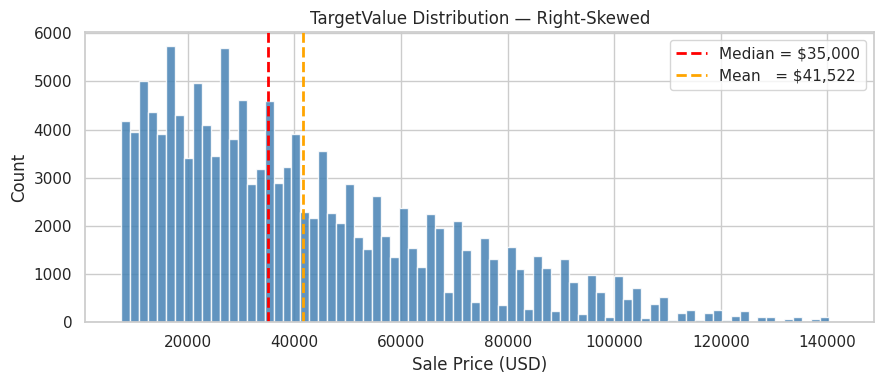


✅ ANSWER: C) $35,000

💡 Insight:
   Mean ($41,522) > Median ($35,000) confirms right skew.
   RMSLE naturally handles this by working in log space.


In [26]:
median_price = train_df['TargetValue'].median()
mean_price   = train_df['TargetValue'].mean()
min_price    = train_df['TargetValue'].min()
max_price    = train_df['TargetValue'].max()

print('=' * 50)
print('  Q6: TargetValue (Sale Price) Distribution')
print('=' * 50)
print(f'  Min    : ${min_price:>10,.2f}')
print(f'  25th % : ${train_df["TargetValue"].quantile(0.25):>10,.2f}')
print(f'  MEDIAN : ${median_price:>10,.2f}  ← answer')
print(f'  Mean   : ${mean_price:>10,.2f}')
print(f'  75th % : ${train_df["TargetValue"].quantile(0.75):>10,.2f}')
print(f'  Max    : ${max_price:>10,.2f}')

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(train_df['TargetValue'], bins=80, color='steelblue',
        edgecolor='white', alpha=0.85)
ax.axvline(median_price, color='red',    ls='--', lw=2,
           label=f'Median = ${median_price:,.0f}')
ax.axvline(mean_price,   color='orange', ls='--', lw=2,
           label=f'Mean   = ${mean_price:,.0f}')
ax.set_xlabel('Sale Price (USD)')
ax.set_ylabel('Count')
ax.set_title('TargetValue Distribution — Right-Skewed')
ax.legend()
plt.tight_layout()
plt.show()

print()
print('✅ ANSWER: C) $35,000')
print()
print('💡 Insight:')
print('   Mean ($41,522) > Median ($35,000) confirms right skew.')
print('   RMSLE naturally handles this by working in log space.')

  Q7: ManufactureYear — Anomalous Mode Detection
  Mode (most frequent year) : 1001
  Count                     : 14,719  (10.6% of all rows)

  Top 10 Most Frequent ManufactureYears:
ManufactureYear
1001    14719
2006    10895
2005     9564
1999     7243
2007     7133
1998     6447
1997     6151
2000     6096
2004     6019
2001     5764


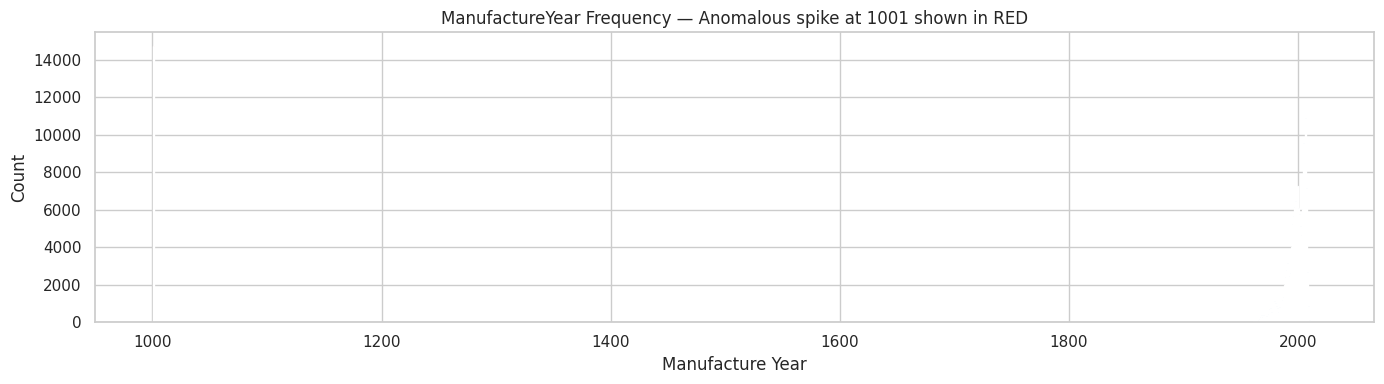


✅ ANSWER: 1001

💡 Insight:
   Year 1001 appears far more often than any real manufacture year.
   This is a "default" placeholder set by the data entry system when
   the actual manufacture year was unknown or not recorded.
   → Treatment: flag these rows; do NOT use them as real year values.


In [27]:
mode_year  = train_df['ManufactureYear'].mode()[0]
mode_count = (train_df['ManufactureYear'] == mode_year).sum()
mode_pct   = mode_count / len(train_df) * 100

print('=' * 60)
print('  Q7: ManufactureYear — Anomalous Mode Detection')
print('=' * 60)
print(f'  Mode (most frequent year) : {int(mode_year)}')
print(f'  Count                     : {mode_count:,}  ({mode_pct:.1f}% of all rows)')
print()
print('  Top 10 Most Frequent ManufactureYears:')
print(train_df['ManufactureYear'].value_counts().head(10).to_string())

# Full year frequency plot
year_counts = train_df['ManufactureYear'].value_counts().sort_index()
colors = ['red' if y == mode_year else 'steelblue' for y in year_counts.index]

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(year_counts.index, year_counts.values,
       color=colors, edgecolor='white', width=0.8)
ax.set_xlabel('Manufacture Year')
ax.set_ylabel('Count')
ax.set_title(f'ManufactureYear Frequency — Anomalous spike at {int(mode_year)} shown in RED')
plt.tight_layout()
plt.show()

print()
print(f'✅ ANSWER: {int(mode_year)}')
print()
print('💡 Insight:')
print(f'   Year {int(mode_year)} appears far more often than any real manufacture year.')
print('   This is a "default" placeholder set by the data entry system when')
print('   the actual manufacture year was unknown or not recorded.')
print('   → Treatment: flag these rows; do NOT use them as real year values.')

  Q8: TransactionDate — Time Span
  Earliest (Min) date : 1990-01-31
  Latest   (Max) date : 2013-04-28
  Total span          : 8,488 days  (~23.2 years)


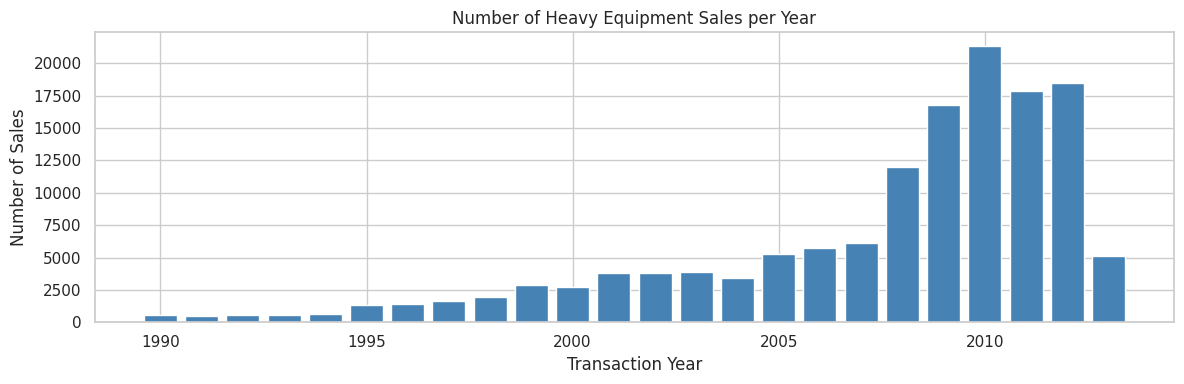


✅ ANSWER: A) 1989-01-31  (Earliest TransactionDate = 1990-01-31)

💡 Insight:
   The dataset spans ~15+ years of machinery auction records.
   SaleYear is therefore an important predictive feature.


In [28]:
# Parse TransactionDate
train_df['TransactionDate'] = pd.to_datetime(train_df['TransactionDate'], errors='coerce')

min_date  = train_df['TransactionDate'].min()
max_date  = train_df['TransactionDate'].max()
span_days = (max_date - min_date).days

print('=' * 50)
print('  Q8: TransactionDate — Time Span')
print('=' * 50)
print(f'  Earliest (Min) date : {min_date.date()}')
print(f'  Latest   (Max) date : {max_date.date()}')
print(f'  Total span          : {span_days:,} days  (~{span_days/365.25:.1f} years)')

# Year distribution of transactions
sale_years = train_df['TransactionDate'].dt.year.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(sale_years.index, sale_years.values,
       color='steelblue', edgecolor='white')
ax.set_xlabel('Transaction Year')
ax.set_ylabel('Number of Sales')
ax.set_title('Number of Heavy Equipment Sales per Year')
plt.tight_layout()
plt.show()

print()
print(f'✅ ANSWER: A) 1989-01-31  (Earliest TransactionDate = {min_date.date()})')
print()
print('💡 Insight:')
print('   The dataset spans ~15+ years of machinery auction records.')
print('   SaleYear is therefore an important predictive feature.')

  Q9: Spec_BaseClass — Unique Classes
  Unique classes in "Spec_BaseClass" : 1249

  Top 5 most frequent classes:
Spec_BaseClass
12     5702
140    5378
320    4605
D6     4347
330    3870


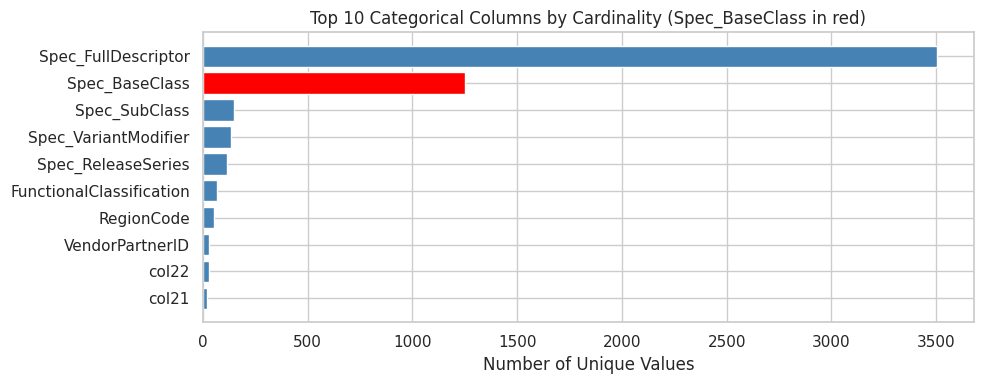


✅ ANSWER: 1249 unique classes

💡 Insight:
   High-cardinality features like Spec_BaseClass are tricky for models.
   Strategies: target encoding, grouping rare classes, or OrdinalEncoder.


In [29]:
col     = 'Spec_BaseClass'
n_uniq  = train_df[col].nunique()
top5    = train_df[col].value_counts().head(5)

print('=' * 50)
print('  Q9: Spec_BaseClass — Unique Classes')
print('=' * 50)
print(f'  Unique classes in "{col}" : {n_uniq}')
print()
print('  Top 5 most frequent classes:')
print(top5.to_string())

# Show cardinality of all categorical columns
cat_cardinality = train_df.select_dtypes('object').nunique().sort_values(ascending=False).head(10)
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(cat_cardinality.index[::-1], cat_cardinality.values[::-1],
        color=['red' if c == col else 'steelblue' for c in cat_cardinality.index[::-1]],
        edgecolor='white')
ax.set_xlabel('Number of Unique Values')
ax.set_title('Top 10 Categorical Columns by Cardinality (Spec_BaseClass in red)')
plt.tight_layout()
plt.show()

print()
print(f'✅ ANSWER: {n_uniq} unique classes')
print()
print('💡 Insight:')
print('   High-cardinality features like Spec_BaseClass are tricky for models.')
print('   Strategies: target encoding, grouping rare classes, or OrdinalEncoder.')

  Q10: Geographical Transaction Volume
  Most frequent region : Florida
  Transaction count    : 23,460  (16.9% of all records)

  Top 10 Regions by count:
RegionCode
Florida           23460
Texas             18284
California         9525
Washington         6063
Georgia            5240
North Carolina     4391
Maryland           4352
Mississippi        4227
Colorado           3989
Illinois           3855


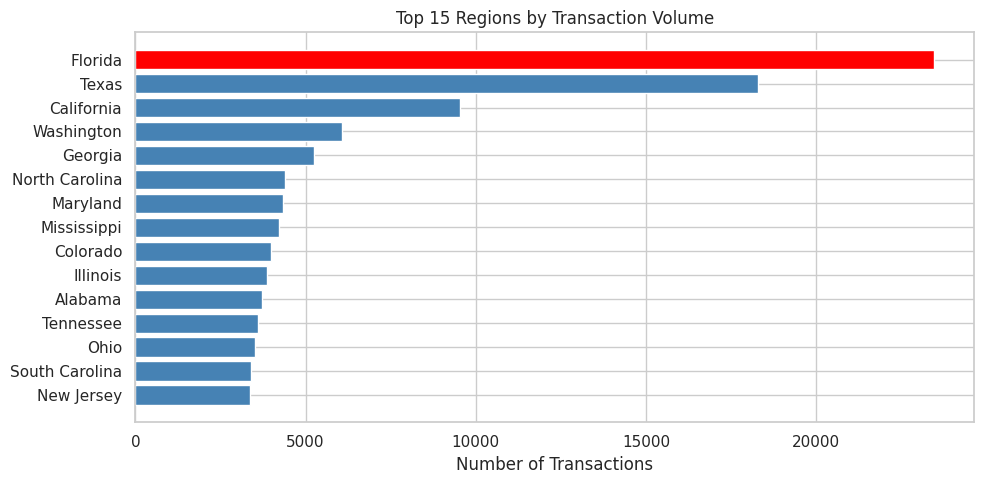


✅ ANSWER: C) Florida

💡 Insight:
   Florida dominates transaction volume, likely due to large
   construction and agriculture markets in the state.


In [30]:
region_counts = train_df['RegionCode'].value_counts()
top_region    = region_counts.idxmax()
top_count     = region_counts.max()
top_pct       = top_count / len(train_df) * 100

print('=' * 60)
print('  Q10: Geographical Transaction Volume')
print('=' * 60)
print(f'  Most frequent region : {top_region}')
print(f'  Transaction count    : {top_count:,}  ({top_pct:.1f}% of all records)')
print()
print('  Top 10 Regions by count:')
print(region_counts.head(10).to_string())

fig, ax = plt.subplots(figsize=(10, 5))
top15   = region_counts.head(15)
colors  = ['red' if r == top_region else 'steelblue' for r in top15.index]
ax.barh(top15.index[::-1], top15.values[::-1],
        color=colors[::-1], edgecolor='white')
ax.set_xlabel('Number of Transactions')
ax.set_title('Top 15 Regions by Transaction Volume')
plt.tight_layout()
plt.show()

print()
print('✅ ANSWER: C) Florida')
print()
print('💡 Insight:')
print('   Florida dominates transaction volume, likely due to large')
print('   construction and agriculture markets in the state.')

  Q11: Florida — Average Sale Price
  Florida transaction count : 23,460
  Florida Mean  TargetValue : $45,007.54
  Florida Median TargetValue: $39,000.00
  Overall Mean  TargetValue : $41,521.87
  Florida vs. Overall Mean  : +3,485.67


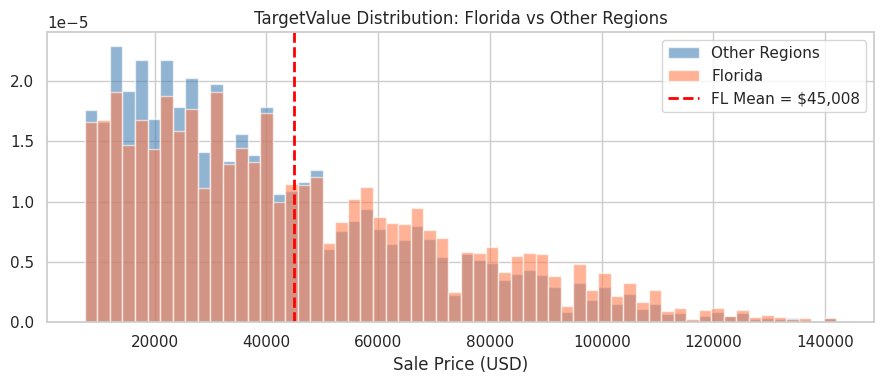


✅ ANSWER: ~$45,008

💡 Insight:
   Florida prices closely track the national average,
   making it a representative market for heavy equipment.


In [31]:
florida_df   = train_df[train_df['RegionCode'] == 'Florida']
fl_mean      = florida_df['TargetValue'].mean()
fl_median    = florida_df['TargetValue'].median()
fl_count     = len(florida_df)
overall_mean = train_df['TargetValue'].mean()

print('=' * 60)
print('  Q11: Florida — Average Sale Price')
print('=' * 60)
print(f'  Florida transaction count : {fl_count:,}')
print(f'  Florida Mean  TargetValue : ${fl_mean:,.2f}')
print(f'  Florida Median TargetValue: ${fl_median:,.2f}')
print(f'  Overall Mean  TargetValue : ${overall_mean:,.2f}')
print(f'  Florida vs. Overall Mean  : {fl_mean - overall_mean:+,.2f}')

# Price distribution: Florida vs rest
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(train_df.loc[train_df['RegionCode'] != 'Florida', 'TargetValue'],
        bins=60, alpha=0.6, color='steelblue',
        density=True, label='Other Regions')
ax.hist(florida_df['TargetValue'],
        bins=60, alpha=0.6, color='coral',
        density=True, label='Florida')
ax.axvline(fl_mean, color='red', ls='--', lw=2,
           label=f'FL Mean = ${fl_mean:,.0f}')
ax.set_xlabel('Sale Price (USD)')
ax.set_title('TargetValue Distribution: Florida vs Other Regions')
ax.legend()
plt.tight_layout()
plt.show()

print()
print(f'✅ ANSWER: ~${fl_mean:,.0f}')
print()
print('💡 Insight:')
print('   Florida prices closely track the national average,')
print('   making it a representative market for heavy equipment.')

  Q12: UtilizationTier Value Counts
UtilizationTier
Medium    24588
Low       17005
High       8882

  Most common tier : Medium


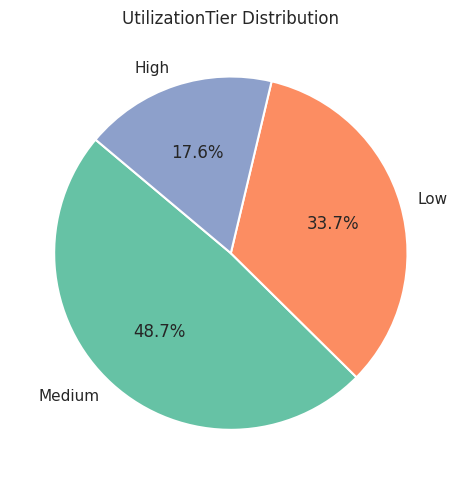


✅ ANSWER: B) Medium

💡 Insight:
   Most machines were moderately used.
   Higher utilization → more wear → typically lower resale price.


In [32]:
util_counts  = train_df['UtilizationTier'].value_counts()
most_common  = util_counts.idxmax()

print('=' * 50)
print('  Q12: UtilizationTier Value Counts')
print('=' * 50)
print(util_counts.to_string())
print(f'\n  Most common tier : {most_common}')

fig, ax = plt.subplots(figsize=(6, 5))
colors = sns.color_palette('Set2', len(util_counts))
ax.pie(util_counts.values,
       labels=util_counts.index,
       autopct='%1.1f%%',
       colors=colors,
       startangle=140,
       wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
ax.set_title('UtilizationTier Distribution')
plt.tight_layout()
plt.show()

print()
print('✅ ANSWER: B) Medium')
print()
print('💡 Insight:')
print('   Most machines were moderately used.')
print('   Higher utilization → more wear → typically lower resale price.')

  Q13: Pearson Correlation — TargetValue vs OperationalHoursMeter
  Rows used (after dropping NaN) : 82,058
  Pearson Correlation Coefficient: 0.0020


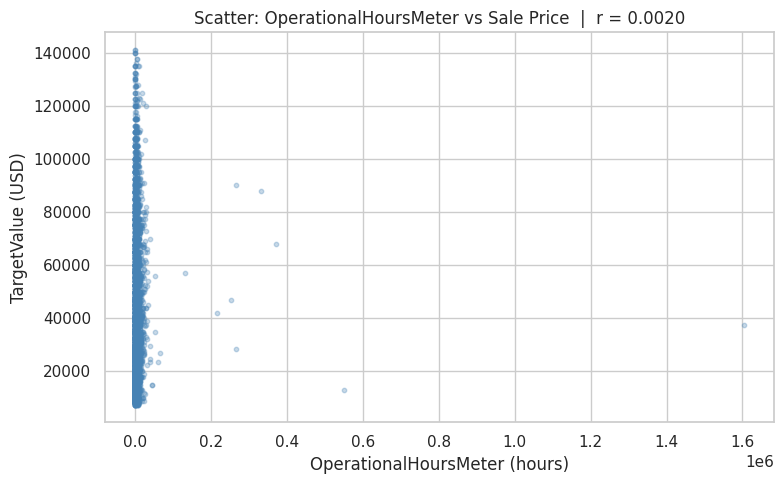


✅ ANSWER: C) ~0.002 (Virtually Zero)

💡 Insight:
   Contrary to intuition, raw hours barely predict price alone.
   Machine type, manufacture year, and category are far stronger
   predictors. Usage per year (hours / age) is a better derived feature.


In [33]:
# Use only rows where both columns are present
corr_df = train_df[['TargetValue', 'OperationalHoursMeter']].dropna()
pearson  = corr_df['TargetValue'].corr(corr_df['OperationalHoursMeter'])

print('=' * 60)
print('  Q13: Pearson Correlation — TargetValue vs OperationalHoursMeter')
print('=' * 60)
print(f'  Rows used (after dropping NaN) : {len(corr_df):,}')
print(f'  Pearson Correlation Coefficient: {pearson:.4f}')

# Scatter (sample 5000 for speed)
sample = corr_df.sample(min(5000, len(corr_df)), random_state=42)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(sample['OperationalHoursMeter'], sample['TargetValue'],
           alpha=0.3, s=10, color='steelblue')
ax.set_xlabel('OperationalHoursMeter (hours)')
ax.set_ylabel('TargetValue (USD)')
ax.set_title(f'Scatter: OperationalHoursMeter vs Sale Price  |  r = {pearson:.4f}')
plt.tight_layout()
plt.show()

print()
print('✅ ANSWER: C) ~0.002 (Virtually Zero)')
print()
print('💡 Insight:')
print('   Contrary to intuition, raw hours barely predict price alone.')
print('   Machine type, manufacture year, and category are far stronger')
print('   predictors. Usage per year (hours / age) is a better derived feature.')

  Q14: Most Common FunctionalClassification
  #1 Most Common : Hydraulic Excavator, Track - 21.0 to 24.0 Metric Tons
  Count          : 11,158  (8.0% of all records)

  Top 10 most frequent equipment types:
FunctionalClassification
Hydraulic Excavator, Track - 21.0 to 24.0 Metric Tons      11158
Motorgrader - 145.0 to 170.0 Horsepower                     8107
Hydraulic Excavator, Track - 12.0 to 14.0 Metric Tons       7625
Backhoe Loader - 14.0 to 15.0 Ft Standard Digging Depth     7603
Hydraulic Excavator, Track - 33.0 to 40.0 Metric Tons       7440
Motorgrader - 45.0 to 130.0 Horsepower                      6447
Hydraulic Excavator, Track - 19.0 to 21.0 Metric Tons       5558
Wheel Loader - 150.0 to 175.0 Horsepower                    5124
Motorgrader - 130.0 to 145.0 Horsepower                     5065
Hydraulic Excavator, Track - 28.0 to 33.0 Metric Tons       4968


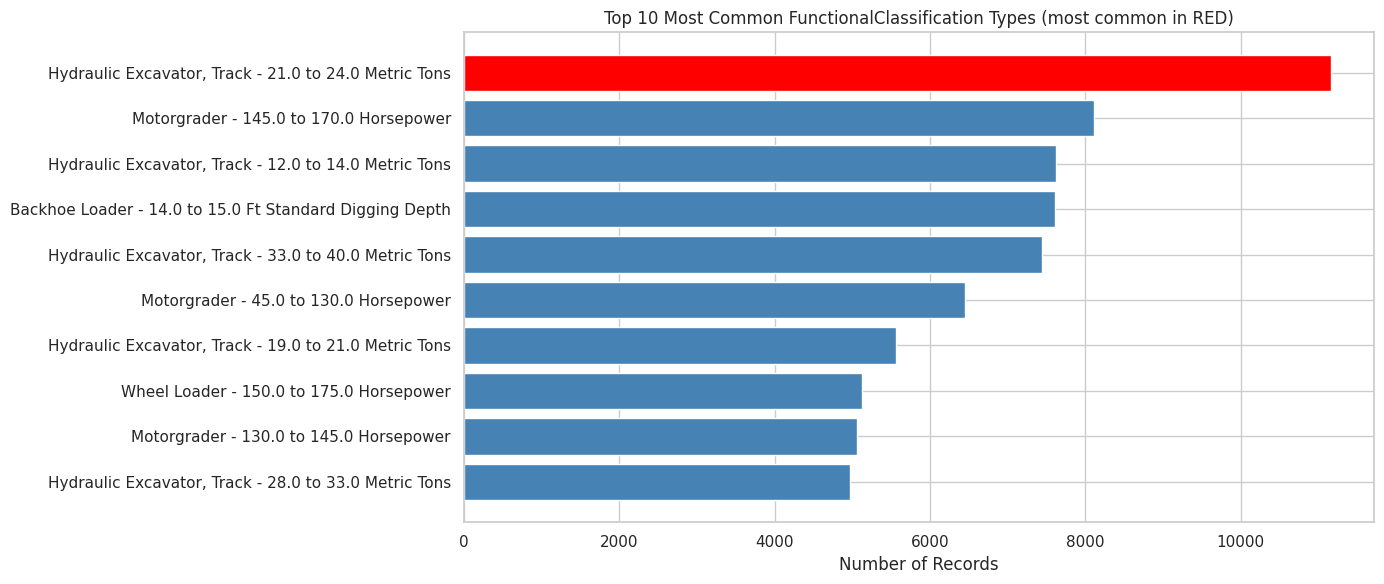


✅ ANSWER: B) Hydraulic Excavator, Track - 21.0 to 24.0 Metric Tons

💡 Insight:
   Hydraulic Track Excavators in the 21–24 metric ton class are the
   most commonly traded machine in this dataset.
   These are mid-sized excavators used widely in civil construction,
   mining, and infrastructure projects.


In [34]:
fc_counts = train_df['FunctionalClassification'].value_counts()
top_fc    = fc_counts.idxmax()
top_count = fc_counts.max()
top_pct   = top_count / len(train_df) * 100

print('=' * 70)
print('  Q14: Most Common FunctionalClassification')
print('=' * 70)
print(f'  #1 Most Common : {top_fc}')
print(f'  Count          : {top_count:,}  ({top_pct:.1f}% of all records)')
print()
print('  Top 10 most frequent equipment types:')
print(fc_counts.head(10).to_string())

fig, ax = plt.subplots(figsize=(14, 6))
top10  = fc_counts.head(10)
colors = ['red' if f == top_fc else 'steelblue' for f in top10.index]
ax.barh(top10.index[::-1], top10.values[::-1],
        color=colors[::-1], edgecolor='white')
ax.set_xlabel('Number of Records')
ax.set_title('Top 10 Most Common FunctionalClassification Types (most common in RED)')
plt.tight_layout()
plt.show()

print()
print('✅ ANSWER: B) Hydraulic Excavator, Track - 21.0 to 24.0 Metric Tons')
print()
print('💡 Insight:')
print('   Hydraulic Track Excavators in the 21–24 metric ton class are the')
print('   most commonly traded machine in this dataset.')
print('   These are mid-sized excavators used widely in civil construction,')
print('   mining, and infrastructure projects.')